In [23]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt # data visualization
import seaborn as sns

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md


# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [24]:
TRAIN_PATH = 'D:/Code/Omahti-oprec/bike-rush-omahti/data/train.csv'
TEST_PATH  = 'D:/Code/Omahti-oprec/bike-rush-omahti/data/test.csv'
SAMPLE_PATH = 'D:/Code/Omahti-oprec/bike-rush-omahti/data/sample_submission.csv'
VALID_PATH = 'D:/Code/Omahti-oprec/bike-rush-omahti/data/valid.csv'

_tr = pd.read_csv(TRAIN_PATH)
_te = pd.read_csv(TEST_PATH)

sample = pd.read_csv(SAMPLE_PATH)

N_TRAIN = len(_tr)

# gabungkan train + test agar cleaning identik; baris test punya target NaN
df_train = pd.concat([_tr, _te], ignore_index=True)
print(df_train.shape, N_TRAIN)

(6665, 15) 4728


In [25]:
pd.set_option('display.max_rows', 100)

In [26]:
df_train.head(20)

,Id,month,day_of_week,hour,temperature_c,humidity_pct,wind_speed_ms,visibility_10m,dew_point_c,solar_radiation_mjm2,rainfall_mm,snowfall_cm,season,holiday,rented_bike_count
0,bk_754f4e10a46336bbbcb9,2,3,14,4.89,49.60,4.11,1174.74,-4.86,1.08,0.00,0.0,Winter,No Holiday,331.0
1,bk_b173e94a44f9021b66a8,2,6,15,-2.40,29.84,2.69,NaN,-17.57,1.38,0.00,0.0,Winter,No Holiday,181.0
2,bk_c2929a145ff14a2b66eb,7,4,14,29.60,62.87,2.77,1923.20,21.52,1.77,0.00,0.0,Summer,No Holiday,999.0
3,bk_bfb1af02d9c8a82b7051,11,2,21,4.33,32.29,1.20,1760.17,-11.32,0.00,0.00,0.0,Autumn,No Holiday,846.0
4,bk_4111f3bffd8d14296138,5,0,19,22.99,56.29,1.91,562.78,13.70,0.32,0.00,0.0,Spring,No Holiday,2236.0
5,bk_d39fb4499a3a94d60c8c,12,1,2,-1.95,69.08,3.43,1976.90,-7.12,NaN,0.00,0.0,Winter,No Holiday,85.0
6,bk_a1dd5f0b6d564a169af9,1,6,5,-2.67,NaN,0.96,1060.21,-11.75,0.00,0.00,0.0,Winter,No Holiday,32.0
7,bk_f8b57b7efee8aa892bf7,6,4,14,27.93,57.82,2.39,775.74,18.51,2.66,0.00,0.0,Summer,No Holiday,1175.0
8,bk_6727dc6ad5e07cc6bed1,10,6,14,18.88,31.48,2.34,1937.88,1.29,2.38,0.00,0.0,Autumn,No Holiday,1767.0
9,bk_85618834e6bc184299ef,1,2,22,-5.46,53.99,1.43,1949.48,-13.58,0.00,0.00,0.0,Winter,No Holiday,291.0


# EDA

Kita cek ada anomali suhu yang berbeda dari rata rata rata untuk setiap musim

C:\Users\azziy\AppData\Local\Temp\ipykernel_25612\1781903856.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\azziy\AppData\Local\Temp\ipykernel_25612\1781903856.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_train, x="season", order=seasons, ax=axes[1, 0], palette="Set2")


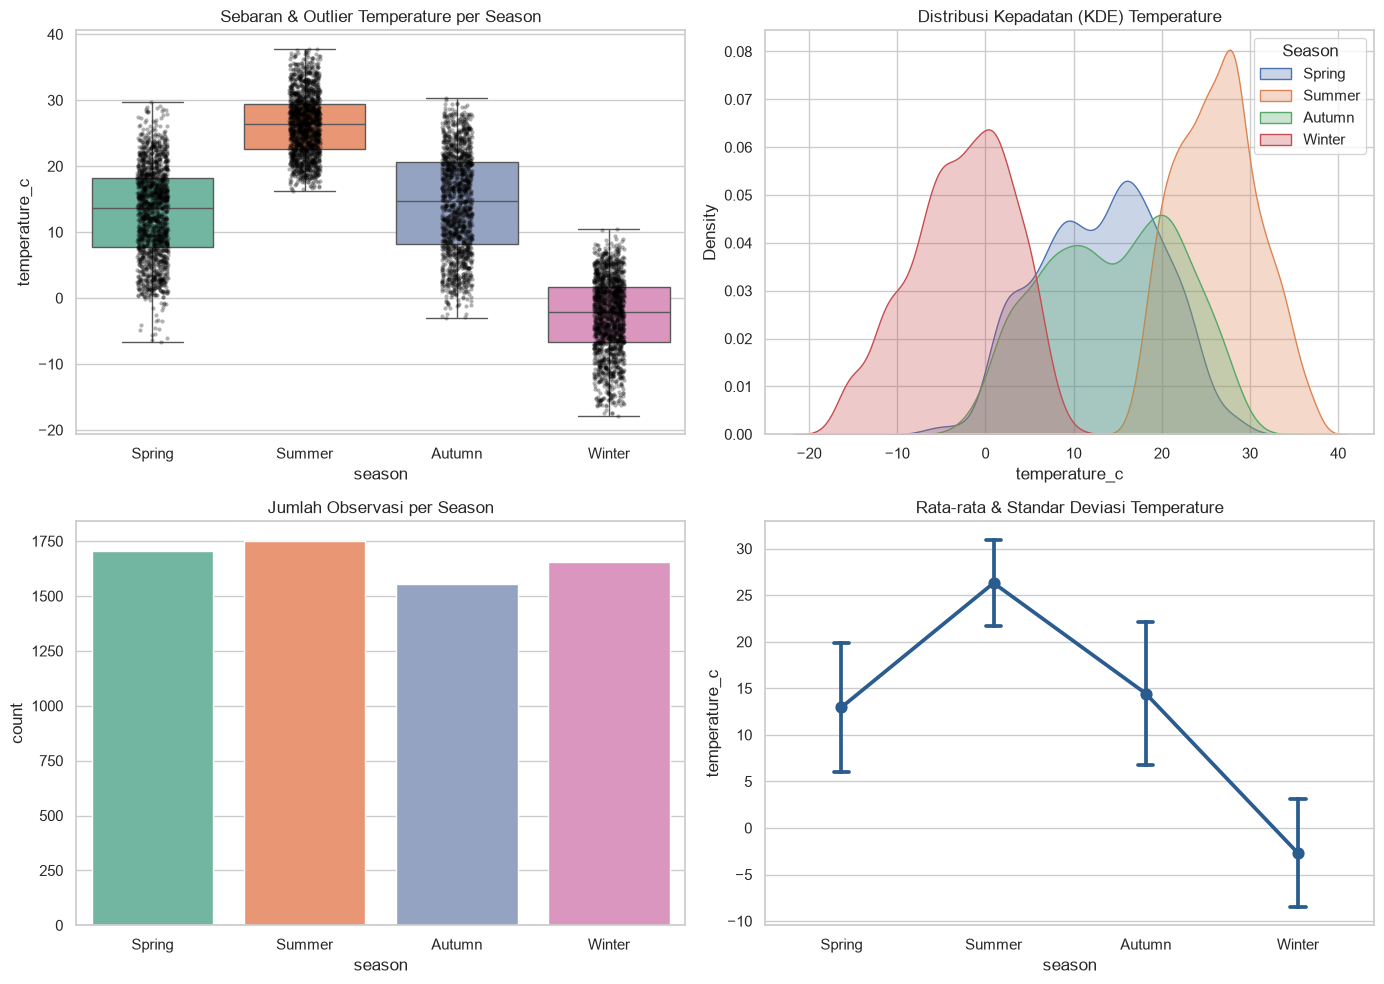

In [27]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# seasons = [1,2,3,4]
seasons = ["Spring","Summer","Autumn","Winter"]


# 1. Boxplot + Stripplot: Deteksi outlier & sebaran per musim
sns.boxplot(
    data=df_train, x="season", y="temperature_c", order=seasons, ax=axes[0, 0], palette="Set2"
)
sns.stripplot(
    data=df_train, x="season", y="temperature_c", order=seasons, ax=axes[0, 0],
    color="black", alpha=0.3, size=3
)
axes[0, 0].set_title("Sebaran & Outlier Temperature per Season")

# 2. KDE Plot: Tumpang tindih distribusi suhu antarmusim
for musim in seasons:
    subset = df_train[df_train["season"] == musim]["temperature_c"].dropna()
    sns.kdeplot(subset, label=musim, fill=True, alpha=0.3, ax=axes[0, 1])
axes[0, 1].set_title("Distribusi Kepadatan (KDE) Temperature")
axes[0, 1].legend(title="Season")

# 3. Countplot: Keseimbangan jumlah data per musim
sns.countplot(data=df_train, x="season", order=seasons, ax=axes[1, 0], palette="Set2")
axes[1, 0].set_title("Jumlah Observasi per Season")

# 4. Rata-rata & Standar Deviasi (Pointplot)
sns.pointplot(
    data=df_train, x="season", y="temperature_c", order=seasons,
    errorbar="sd", capsize=0.1, ax=axes[1, 1], color="#2b5c8f"
)
axes[1, 1].set_title("Rata-rata & Standar Deviasi Temperature")

plt.tight_layout()
plt.show()

Kita cek ada anomali suhu yang berbeda dari rata rata rata untuk setiap musim

C:\Users\azziy\AppData\Local\Temp\ipykernel_25612\1980772207.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\azziy\AppData\Local\Temp\ipykernel_25612\1980772207.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_train, x="month", order=month, ax=axes[1, 0], palette="Set2")


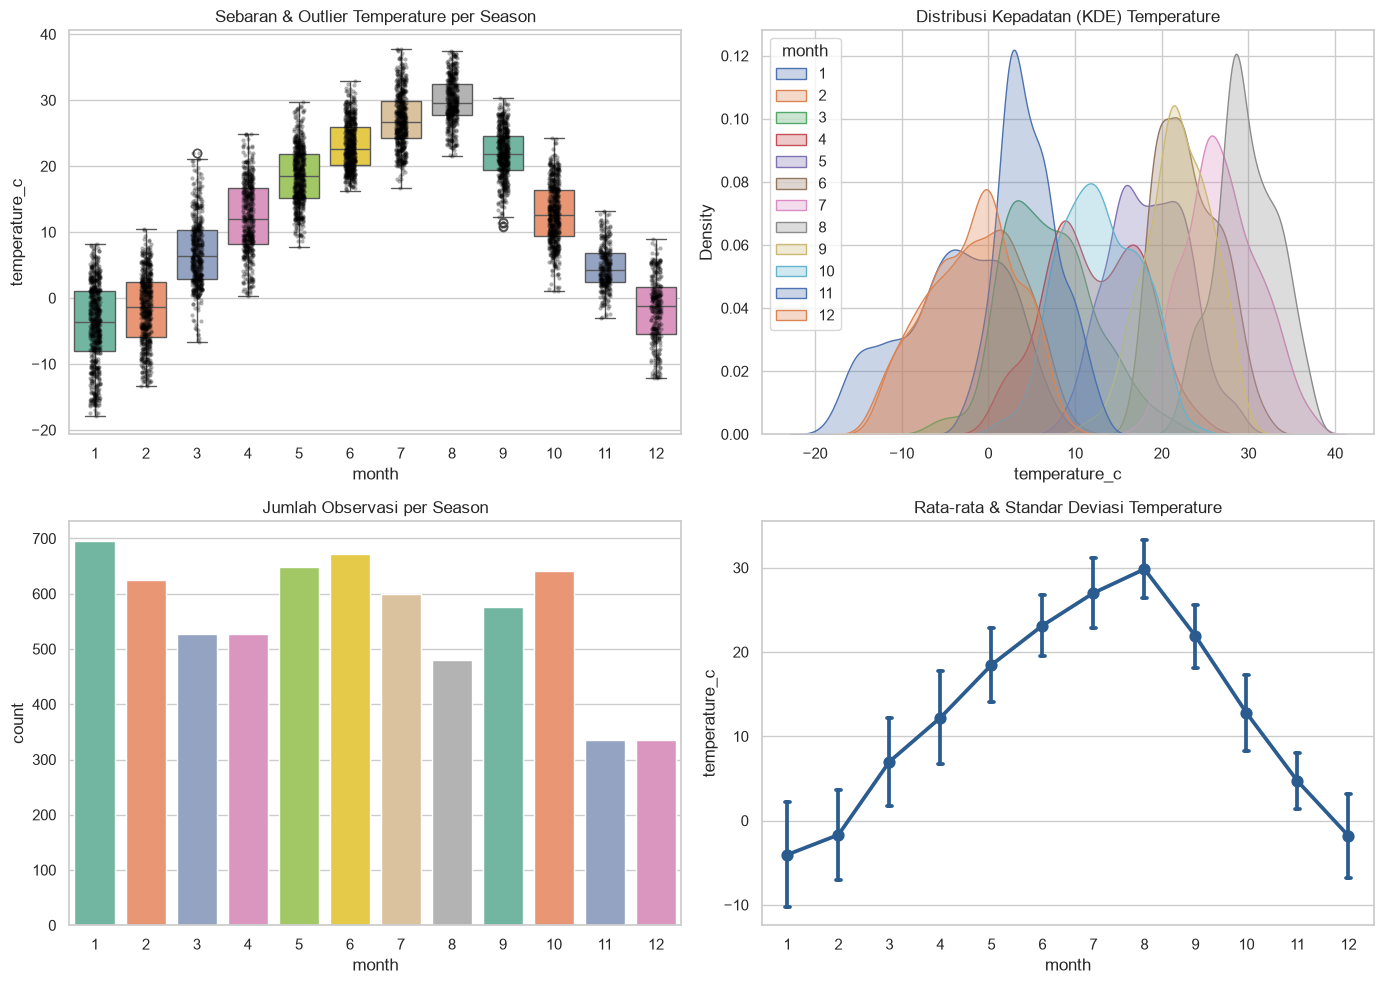

In [28]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

month = [1,2,3,4,5,6,7,8,9,10,11,12]


# 1. Boxplot + Stripplot: Deteksi outlier & sebaran per musim
sns.boxplot(
    data=df_train, x="month", y="temperature_c", order=month, ax=axes[0, 0], palette="Set2"
)
sns.stripplot(
    data=df_train, x="month", y="temperature_c", order=month, ax=axes[0, 0],
    color="black", alpha=0.3, size=3
)
axes[0, 0].set_title("Sebaran & Outlier Temperature per Season")

# 2. KDE Plot: Tumpang tindih distribusi suhu antarmusim
for musim in month:
    subset = df_train[df_train["month"] == musim]["temperature_c"].dropna()
    sns.kdeplot(subset, label=musim, fill=True, alpha=0.3, ax=axes[0, 1])
axes[0, 1].set_title("Distribusi Kepadatan (KDE) Temperature")
axes[0, 1].legend(title="month")

# 3. Countplot: Keseimbangan jumlah data per musim
sns.countplot(data=df_train, x="month", order=month, ax=axes[1, 0], palette="Set2")
axes[1, 0].set_title("Jumlah Observasi per Season")

# 4. Rata-rata & Standar Deviasi (Pointplot)
sns.pointplot(
    data=df_train, x="month", y="temperature_c", order=month,
    errorbar="sd", capsize=0.1, ax=axes[1, 1], color="#2b5c8f"
)
axes[1, 1].set_title("Rata-rata & Standar Deviasi Temperature")

plt.tight_layout()
plt.show()

In [29]:
df_train.isnull().sum()

Id                         0
month                      0
day_of_week                0
hour                       0
temperature_c            167
humidity_pct             140
wind_speed_ms            161
visibility_10m           171
dew_point_c              180
solar_radiation_mjm2     165
rainfall_mm              155
snowfall_cm              157
season                     0
holiday                    0
rented_bike_count       1937
dtype: int64

# Data Cleaning

### Column Holiday
Replaec

In [31]:
df_train['holiday'] = df_train['holiday'].replace('No Holiday','0').replace('Holiday','1').astype(int)
df_train['holiday'].value_counts()

holiday
0    6305
1     360
Name: count, dtype: int64

### Column Seasons

In [32]:
df_train['season'].value_counts()

season
Summer    1752
Spring    1704
Winter    1656
Autumn    1553
Name: count, dtype: int64

In [33]:
df_train['season'] = df_train['season'].replace('Spring','1').replace('Summer','2').replace('Winter','3').replace('Autumn','4').astype(int)

### Column Month day and hour

In [34]:
df_train['month'].value_counts()

month
1     696
6     672
5     648
10    641
2     624
7     600
9     576
3     528
4     528
8     480
11    336
12    336
Name: count, dtype: int64

### Missing Value

In [35]:
df_train = df_train.fillna(0)

### Column

# Feature Engineering

Mengisi Misiing valude `temperature_c` dengan rata rata untuk setiap seasons

In [37]:
df_train["temperature_c"] = df_train["temperature_c"].fillna(
    df_train.groupby("season")["temperature_c"].transform("median"))

Buat feature diff 

# Model Training

In [38]:
# Split data again
train_clean = df_train.iloc[:N_TRAIN].copy()
test_clean = df_train.iloc[N_TRAIN:].drop(columns=['rented_bike_count']).reset_index(drop=True)

In [47]:
features = train_clean.select_dtypes(include=[np.number]).columns.drop(['id', 'rented_bike_count'], errors='ignore')

In [48]:
from sklearn.ensemble import (
    HistGradientBoostingRegressor, 
    RandomForestRegressor
)
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures

x = train_clean[features]
y = train_clean['rented_bike_count']

# Show Score
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=432
)

model = HistGradientBoostingRegressor()
model.fit(x_train,y_train)
target = test_clean[features].fillna(0)

y_pred = model.predict(x_test)
r2 = r2_score(y_test,y_pred)

print(r2)

0.9448733855989522


### Make submission file

In [49]:
# # Submission Predict
# final = model.predict(target)
# submission = pd.DataFrame({
#     'Id': test_clean['Id'],
#     'rented_bike_count': np.clip(final, a_min=0, a_max=None)
# })

# submission.to_csv('/kaggle/working/submission.csv', index=False)
# print("Score : ",r2)
# print("✅ Selesai! File 'submission.csv' berhasil dibuat.")

In [50]:
    'Id': test_clean['Id'],
    'rented_bike_count': np.clip(final, a_min=0, a_max=None)
})

submission.to_csv('/kaggle/working/submission.csv', index=False)
print("Score : ",r2)
print("✅ Selesai! File 'submission.csv' berhasil dibuat.")

IndentationError: unexpected indent (1587053397.py, line 1)